# Air Gesture Recognition - MLP Classifier
### PRJ303

In [ ]:
 # ================== MOUNT GOOGLE DRIVE ==================
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
!pip install mediapipe==0.10.13 -q
print('All dependencies installed!')

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 35.6/35.6 MB 40.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 295.2/295.2 kB 21.0 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
opentelemetry-proto 1.38.0 requires protobuf<7.0,>=5.0, but you have protobuf 4.25.9 which is incompatible.
grain 0.2.16 requires protobuf>=5.28.3, but you have protobuf 4.25.9 which is incompatible.
ydf 0.15.0 requires protobuf<7.0.0,>=5.29.1, but you have protobuf 4.25.9 which is incompatible.
grpcio-status 1.71.2 requires protobuf<6.0dev,>=5.26.1, but you have protobuf 4.25.9 which is incompatible.
All dependencies installed!


In [ ]:
# ================== IMPORTS ==================
import numpy as np
import os
import joblib
import cv2
import mediapipe as mp
from mediapipe.tasks import python
from collections import deque

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

import matplotlib.pyplot as plt
import seaborn as sns

print('All imports successful!')

All imports successful!


In [ ]:
# ================== DATASET PATH (Shared Drive) ==================
# Path to the shared drive dataset folder
data_path = '/content/drive/Shareddrives/PRJ303_Dataset/dataset/'

# Verify the path exists and show contents
if os.path.exists(data_path):
    print('Dataset folder found!')
    print('Contents:', os.listdir(data_path))
else:
    print('ERROR: Path not found!')
    print('Available drives:')
    print(os.listdir('/content/drive/'))

Dataset folder found!
Contents: ['erase', 'screenshot', 'clear', 'draw', 'color', 'scroll', 'cursor']


In [ ]:
# ================== LOAD DATASET ==================
X = []
y = []

for label in os.listdir(data_path):
    class_path = os.path.join(data_path, label)

    if os.path.isdir(class_path):
        for file in os.listdir(class_path):
            if file.endswith('.npy'):
                file_path = os.path.join(class_path, file)
                data = np.load(file_path)
                X.append(data)
                y.append(label)

# Check if data was loaded
if len(X) == 0:
    raise ValueError('No .npy files found! Check your dataset folder structure.')

# Convert to numpy arrays
X = np.array(X)
y = np.array(y)

# Flatten to 2D: (samples, features)
X = X.reshape(len(X), -1)

print('Dataset Shape:', X.shape)
print('Labels found:', np.unique(y))
print('Total samples:', len(y))

Dataset Shape: (700, 6300)
Labels found: ['clear' 'color' 'cursor' 'draw' 'erase' 'screenshot' 'scroll']
Total samples: 700


In [ ]:
# ================== ENCODE LABELS ==================
le = LabelEncoder()
y_encoded = le.fit_transform(y)
print('Classes:', le.classes_)

Classes: ['clear' 'color' 'cursor' 'draw' 'erase' 'screenshot' 'scroll']


In [ ]:
# ================== SCALING ==================
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [ ]:
# ================== TRAIN TEST SPLIT ==================
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y_encoded, test_size=0.2, random_state=42, stratify=y_encoded
)

print('Train size:', X_train.shape)
print('Test size:', X_test.shape)

Train size: (560, 6300)
Test size: (140, 6300)


In [ ]:
# ================== MLP MODEL ==================
param_grid = {
    'hidden_layer_sizes': [(64,), (128,), (64, 32)],
    'activation': ['relu'],
    'solver': ['adam'],
    'max_iter': [300]
}

mlp = MLPClassifier(random_state=42)

grid = GridSearchCV(mlp, param_grid, cv=3, n_jobs=-1, verbose=1)
grid.fit(X_train, y_train)

best_model = grid.best_estimator_
print('\nBest Parameters:', grid.best_params_)

Fitting 3 folds for each of 3 candidates, totalling 9 fits

Best Parameters: {'activation': 'relu', 'hidden_layer_sizes': (64,), 'max_iter': 300, 'solver': 'adam'}


Accuracy: 0.9571428571428572

Classification Report:
              precision    recall  f1-score   support

       clear       1.00      1.00      1.00        20
       color       0.91      1.00      0.95        20
      cursor       0.95      0.95      0.95        20
        draw       0.95      1.00      0.98        20
       erase       1.00      0.85      0.92        20
  screenshot       0.91      1.00      0.95        20
      scroll       1.00      0.90      0.95        20

    accuracy                           0.96       140
   macro avg       0.96      0.96      0.96       140
weighted avg       0.96      0.96      0.96       140



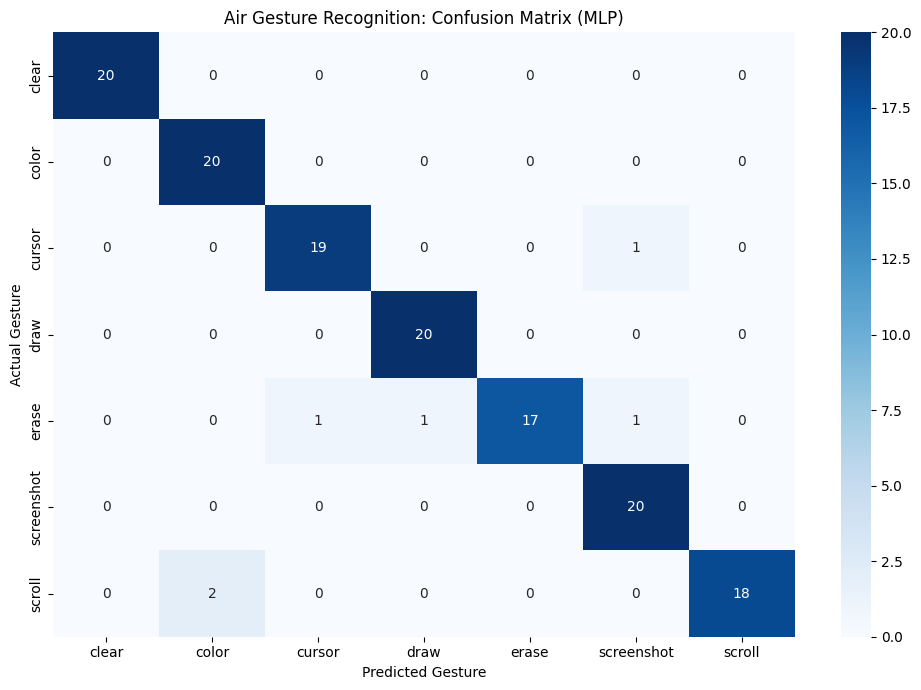

In [ ]:
# ================== EVALUATION ==================
y_pred = best_model.predict(X_test)

print('Accuracy:', accuracy_score(y_test, y_pred))
print('\nClassification Report:')
print(classification_report(y_test, y_pred, target_names=le.classes_))

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(10, 7))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=le.classes_, yticklabels=le.classes_)
plt.title('Air Gesture Recognition: Confusion Matrix (MLP)')
plt.xlabel('Predicted Gesture')
plt.ylabel('Actual Gesture')
plt.tight_layout()
plt.show()

In [ ]:
# ================== SAVE MODEL ==================
save_path = '/content/drive/Shareddrives/PRJ303_Dataset/'

joblib.dump(best_model, save_path + 'gesture_model_mlp.pkl')
joblib.dump(scaler, save_path + 'scaler_mlp.pkl')
joblib.dump(le, save_path + 'label_encoder.pkl')

print('Model saved successfully to Shared Drive!')

Model saved successfully to Shared Drive!


## Real-Time Gesture Recognition (Colab Compatible)
This uses your browser webcam — no local setup needed!

In [ ]:
# ================== STEP 1: Install & Import for Colab Webcam ==================
from google.colab import drive
from google.colab.patches import cv2_imshow  # Colab-compatible display
from IPython.display import display, Javascript, Image
from base64 import b64decode, b64encode
import cv2
import numpy as np
import mediapipe as mp
import joblib
from collections import deque
from PIL import Image as PILImage
import io
import io

print('Imports done!')

Imports done!


In [ ]:
# ================== STEP 2: Load Saved Models ==================
save_path = '/content/drive/Shareddrives/PRJ303_Dataset/'

model    = joblib.load(save_path + 'gesture_model_mlp.pkl')
scaler_rt = joblib.load(save_path + 'scaler_mlp.pkl')
le_rt    = joblib.load(save_path + 'label_encoder.pkl')

print('Models loaded!')
print('Gesture classes:', le_rt.classes_)

Models loaded!
Gesture classes: ['clear' 'color' 'cursor' 'draw' 'erase' 'screenshot' 'scroll']


In [ ]:
# ================== STEP 3: Capture Photo from Browser Webcam ==================
# This JS code opens your webcam in the browser and takes a snapshot

def take_photo(filename='photo.jpg', quality=0.8):
    js = Javascript('''
    async function takePhoto(quality) {
        const div = document.createElement('div');
        const capture = document.createElement('button');
        capture.textContent = 'Capture Gesture';
        capture.style.fontSize = '18px';
        capture.style.padding = '10px 20px';
        capture.style.margin = '10px';
        div.appendChild(capture);

        const video = document.createElement('video');
        video.style.display = 'block';
        const stream = await navigator.mediaDevices.getUserMedia({video: true});
        document.body.appendChild(div);
        div.appendChild(video);
        video.srcObject = stream;
        await video.play();

        google.colab.output.setIframeHeight(document.documentElement.scrollHeight, true);

        await new Promise((resolve) => capture.onclick = resolve);

        const canvas = document.createElement('canvas');
        canvas.width = video.videoWidth;
        canvas.height = video.videoHeight;
        canvas.getContext('2d').drawImage(video, 0, 0);
        stream.getVideoTracks()[0].stop();
        div.remove();
        return canvas.toDataURL('image/jpeg', quality);
    }
    ''')
    display(js)

    from google.colab.output import eval_js
    data = eval_js(f'takePhoto({quality})')
    binary = b64decode(data.split(',')[1])
    with open(filename, 'wb') as f:
        f.write(binary)
    return filename

print('Camera function ready! Run the next cell to capture.')

Camera function ready! Run the next cell to capture.


In [ ]:
# ================== STEP 4: Feature Extraction Function ==================
mp_hands = mp.solutions.hands
mp_draw  = mp.solutions.drawing_utils
gesture_buffer = deque(maxlen=10)

def extract_features_two_hands(results):
    left_hand  = np.zeros(63)
    right_hand = np.zeros(63)

    if results.multi_hand_landmarks and results.multi_handedness:
        for hand_landmarks, handedness in zip(
            results.multi_hand_landmarks, results.multi_handedness
        ):
            hand_features = []
            for lm in hand_landmarks.landmark:
                hand_features.extend([lm.x, lm.y, lm.z])

            # FLIPPED: swap Left and Right because of cv2.flip
            if handedness.classification[0].label == 'Left':
                right_hand = np.array(hand_features)  # ← swapped
            else:
                left_hand = np.array(hand_features)   # ← swapped

    return np.concatenate([left_hand, right_hand]).reshape(1, -1)

print('Feature extractor ready!')

Feature extractor ready!


<IPython.core.display.Javascript object>

All class probabilities:
  clear: 0.0%
  color: 100.0%
  cursor: 0.0%
  draw: 0.0%
  erase: 0.0%
  screenshot: 0.0%
  scroll: 0.0%


/usr/local/lib/python3.12/dist-packages/google/protobuf/symbol_database.py:55: UserWarning: SymbolDatabase.GetPrototype() is deprecated. Please use message_factory.GetMessageClass() instead. SymbolDatabase.GetPrototype() will be removed soon.
  warnings.warn('SymbolDatabase.GetPrototype() is deprecated. Please '


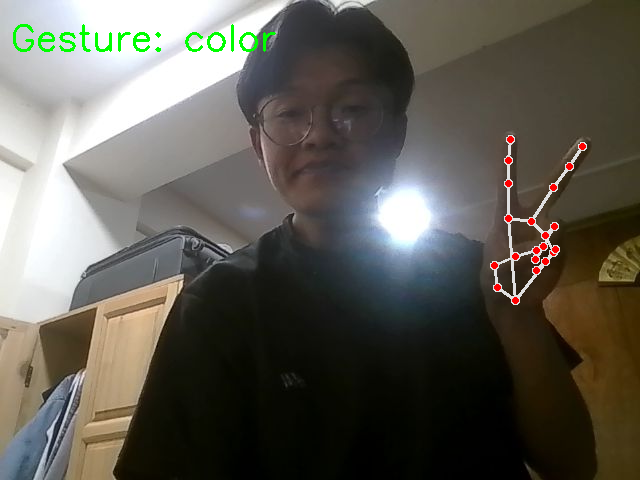


Predicted Gesture: color


In [ ]:
# CELL 15 - Capture single photo & predict
gesture_buffer.clear()  # ← clear old predictions every run

filename = take_photo('gesture_capture.jpg')

frame = cv2.imread(filename)
frame = cv2.flip(frame, 1)
rgb   = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)

with mp_hands.Hands(
    max_num_hands=2,
    min_detection_confidence=0.7,
    min_tracking_confidence=0.7
) as hands:
    result = hands.process(rgb)

    if result.multi_hand_landmarks:
        for hand_landmarks in result.multi_hand_landmarks:
            mp_draw.draw_landmarks(frame, hand_landmarks, mp_hands.HAND_CONNECTIONS)

        single_frame = extract_features_two_hands(result).flatten()
        SEQUENCE_LENGTH = 6300 // len(single_frame)
        full_sequence = np.tile(single_frame, SEQUENCE_LENGTH).reshape(1, -1)
        full_sequence_scaled = scaler_rt.transform(full_sequence)

        raw_prediction = model.predict(full_sequence_scaled)[0]
        gesture_name   = le_rt.inverse_transform([raw_prediction])[0]

        print('All class probabilities:')
        for name, prob in zip(le_rt.classes_, model.predict_proba(full_sequence_scaled)[0]):
            print(f'  {name}: {prob*100:.1f}%')

    else:
        gesture_name = 'No Hand Detected'

cv2.putText(frame, f'Gesture: {gesture_name}',
            (10, 50), cv2.FONT_HERSHEY_SIMPLEX, 1.2, (0, 255, 0), 2)

cv2_imshow(frame)
print(f'\nPredicted Gesture: {gesture_name}')